<a href="https://colab.research.google.com/github/mhabibier/scikit-learn-cookbook/blob/main/13_Deploying_scikit_learn_Models_in_Production.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 13 — Deploying scikit-learn Models in Production

**scikit-learn Cookbook, Third Edition — John Sukup (Packt, 2025)**  
**Nama:** Muhammad Habibie Rabbani · **Kelas:** TK-47-04

## Tujuan pembelajaran
Menyimpan pipeline beserta skema dan versi, memverifikasi model setelah reload, mengukur biaya inferensi, memantau aliran data, dan menjalankan simulasi pemeriksaan kelayakan rilis dengan validation yang terpisah.

## Peta reproduksi
Notebook ini mengadaptasi notebook bab utama dan *Exercise Solutions* dari [kode pendamping resmi](https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition/tree/c624b1279cf23a83273e806cede15cad0c9e5500), commit `c624b1279cf23a83273e806cede15cad0c9e5500`. Penjelasan ditulis ulang dalam Bahasa Indonesia; kode disesuaikan agar dapat dijalankan pada lingkungan yang dicatat di bawah. Penomoran bagian mengikuti alur konsep sumber, bukan nomor halaman PDF. Buku tetap referensi utama untuk membaca uraian lengkap.

| Resep sumber | Bagian |
|---|---|
| Deployment considerations | 1 |
| Serializing with pickle/joblib | 2 |
| Performance optimization | 3 |
| Monitoring and updating | 4 |
| Versioning and reproducibility | 5 |
| Automated deployment checks | 6 |
| Exercises 1–3 | 7–9 |

## Penyesuaian dan batas reproduksi
Semua kegiatan merupakan **simulasi lokal**, tanpa publish layanan atau mengubah GitHub. Split dilakukan sebelum fit. Skor validation tidak dihitung pada data yang sudah dipakai training. Versi library diambil dari lingkungan sebenarnya. Label acak dari sumber tidak digunakan sebagai benchmark model. Stream memakai relasi target yang sama, lalu shift terkontrol; mengganti seed `make_classification` secara terpisah dapat mengganti fungsi target dan bukan simulasi drift yang terdefinisi. File model dibuat saat notebook dijalankan di folder `generated_models/ch13`; paket unduhan tidak memerlukan file model biner yang sudah jadi.

## Cara menjalankan
Jalankan **Restart Kernel → Run All** dari atas ke bawah. Setiap notebook mandiri. Gunakan Python 3.12 dan paket dalam `requirements.txt`; versi yang benar-benar dipakai tampil di sel pertama. Dataset tersedia melalui scikit-learn atau generator sintetis; tidak memerlukan unduhan data tambahan setelah paket terpasang.

Untuk Google Colab: unggah `.ipynb`, instal versi paket yang diperlukan bila berbeda, lalu **Restart session → Run all**. Pengujian paket ini dilakukan dengan proses IPython baru per notebook, bukan melalui antarmuka Colab.

In [ ]:
%matplotlib inline
import sys, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, f1_score

SEED = 2024
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 115, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 16)
pd.set_option('display.precision', 4)
print({'Python': platform.python_version(), 'scikit-learn': sklearn.__version__,
       'NumPy': np.__version__, 'pandas': pd.__version__, 'seed': SEED})

def audit_numeric(X, y=None, name='data'):
    frame = pd.DataFrame(X)
    print(name, {'shape': frame.shape, 'missing': int(frame.isna().sum().sum()),
                 'duplicate_rows': int(frame.duplicated().sum()),
                 'all_finite': bool(np.isfinite(frame.to_numpy(dtype=float)).all())})
    if y is not None and np.asarray(y).ndim == 1:
        display(pd.Series(y).value_counts().sort_index().rename('jumlah').to_frame())

def report(y_true, y_pred, names=None):
    result = classification_report(y_true, y_pred, target_names=names, output_dict=True, zero_division=0)
    overall_accuracy = result.pop('accuracy', None)
    display(pd.DataFrame(result).T)
    if overall_accuracy is not None:
        print(f'Overall accuracy: {overall_accuracy:.4f} (n={len(y_true)})')

def metrics(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred),
            'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
            'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0)}

{'Python': '3.12.14', 'scikit-learn': '1.8.0', 'NumPy': '2.3.5', 'pandas': '2.2.3', 'seed': 2024}


## 1. Model deployment adalah kontrak data dan proses
Model yang baik pada notebook belum otomatis layak digunakan pada sistem nyata. Inferensi perlu menerima fitur dalam jumlah, urutan, satuan, dan preprocessing yang sama dengan training. Menyimpan classifier saja sementara scaler dibangun ulang pada data masuk akan mengubah prediksi.

Pipeline menyatukan transformasi dan estimator. Artefak rilis perlu disertai skema fitur, arti kelas, versi dependensi, identitas data/split, parameter, hasil validasi dan prosedur rollback. Notebook ini menunjukkan inferensi lokal dan pengecekan kontrak; tidak membuka server web. Sampel permintaan diambil dari holdout asli, bukan vektor uniform dengan label acak.

Kita memakai 1.000 sampel dan 20 fitur sumber. Split training/test dipisahkan sebelum fit. Test hanya untuk verifikasi model yang sudah ditetapkan. `predict_proba` bukan jaminan probabilitas terkalibrasi; untuk keputusan berbiaya tinggi perlu evaluasi kalibrasi/domain yang relevan.

In [ ]:
import json, hashlib, pickle, copy, os
from pathlib import Path
from joblib import dump, load
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

model_dir=Path('generated_models')/'ch13'; model_dir.mkdir(parents=True,exist_ok=True)
artifact_dir=Path('artifacts'); artifact_dir.mkdir(exist_ok=True)
X,y=make_classification(n_samples=1000,n_features=20,random_state=SEED)
Xt,Xv,yt,yv=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
pipe=make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000,random_state=SEED)).fit(Xt,yt)
model_path=model_dir/'logistic_pipeline.joblib'; dump(pipe,model_path)
loaded=load(model_path)  # Hanya artefak yang baru kita buat sendiri.
assert np.array_equal(pipe.predict(Xv),loaded.predict(Xv))
assert np.allclose(pipe.predict_proba(Xv),loaded.predict_proba(Xv),rtol=0,atol=1e-12)
feature_schema=[f'feature_{i:02d}' for i in range(X.shape[1])]

def predict_request(frame,model,schema):
    if not isinstance(frame,pd.DataFrame) or list(frame.columns)!=schema:
        raise ValueError('Nama dan urutan kolom harus tepat sesuai skema.')
    values=frame.to_numpy(dtype=float)
    if len(values)==0 or values.shape[1]!=model.n_features_in_ or not np.isfinite(values).all():
        raise ValueError('Input harus tidak kosong, berdimensi sesuai, dan finite.')
    return {'prediction':model.predict(values).tolist(),'probability':model.predict_proba(values).tolist(),
            'classes':model.classes_.tolist()}

request=pd.DataFrame(Xv[:3],columns=feature_schema)
print('Inferensi lokal:',predict_request(request,loaded,feature_schema))
try: predict_request(request.iloc[:,:-1],loaded,feature_schema)
except ValueError as exc: print('Uji input tidak valid: ditolak sesuai rancangan →',exc)
print('Model tetap setelah reload:',metrics(yv,loaded.predict(Xv)))

Inferensi lokal: {'prediction': [0, 1, 0], 'probability': [[0.993329743714465, 0.006670256285534986], [0.49257259905787953, 0.5074274009421205], [0.8803362101266414, 0.11966378987335861]], 'classes': [0, 1]}
Uji input tidak valid: ditolak sesuai rancangan → Nama dan urutan kolom harus tepat sesuai skema.
Model tetap setelah reload: {'accuracy': 0.86, 'balanced_accuracy': 0.8597859785978598, 'macro_f1': 0.859873886497848}


## 2. Serialisasi pickle dan joblib
Pickle menyimpan objek Python beserta state-nya. Joblib praktis untuk objek dengan array NumPy besar dan dapat menggunakan kompresi. Keduanya tidak menjamin kompatibilitas antarrilis scikit-learn; gunakan lingkungan yang sama dengan training dan catat versinya.

**Memuat pickle/joblib dari sumber yang tidak dipercaya dapat menjalankan kode.** Dalam latihan ini, hanya file yang baru dibuat sendiri pada sel yang sama yang dimuat. SHA-256 memeriksa integritas byte, bukan membuktikan pihak pembuat dapat dipercaya. Untuk pertukaran artefak dengan batas kepercayaan berbeda, evaluasi format yang lebih terbatas seperti skops/ONNX sesuai dukungan estimator; format tersebut tidak dipakai sebagai dependensi latihan ini.

RF sumber menggunakan 500 sampel, 15 fitur, 10 pohon. Kedua format diuji dengan kesamaan label dan probabilitas pada holdout. Ukuran file bergantung model dan kompresi, bukan indikator akurasi.

In [ ]:
R,ry=make_classification(n_samples=500,n_features=15,random_state=SEED)
Rt,Rv,rt,rv=train_test_split(R,ry,test_size=.3,stratify=ry,random_state=SEED)
rf=RandomForestClassifier(n_estimators=10,random_state=SEED,n_jobs=1).fit(Rt,rt)
pickle_path=model_dir/'rf.pkl'; joblib_path=model_dir/'rf.joblib'
with pickle_path.open('wb') as f: pickle.dump(rf,f,protocol=pickle.HIGHEST_PROTOCOL)
dump(rf,joblib_path)
with pickle_path.open('rb') as f: from_pickle=pickle.load(f)
from_joblib=load(joblib_path)
for m in [from_pickle,from_joblib]:
    assert np.array_equal(rf.predict(Rv),m.predict(Rv))
    assert np.allclose(rf.predict_proba(Rv),m.predict_proba(Rv),rtol=0,atol=1e-12)
display(pd.DataFrame([{'format':p.suffix,'KiB':p.stat().st_size/1024,
    'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in [pickle_path,joblib_path]]))
print('RF reload checks passed:',metrics(rv,from_joblib.predict(Rv)))

RF reload checks passed: {'accuracy': 0.9066666666666666, 'balanced_accuracy': 0.9066666666666667, 'macro_f1': 0.9066500711237553}


,format,KiB,sha256
0,.pkl,47.6270,84c7003c391c99424e9d4594ad1e23586873163ff5f27c...
1,.joblib,48.7744,9b57da7840920b6e6872ca67589d9789d6337bee9d62dc...


## 3. Performa: batch inferensi, parallelism dan pengukuran
Batch prediction mengurangi overhead pemanggilan per sampel. Latency mengukur waktu satu permintaan/batch; throughput mengukur jumlah sampel per detik. Keduanya tidak identik. Lakukan warm-up dan beberapa pengulangan memakai timer monotonic (`perf_counter`) agar satu pengukuran tidak terlalu dominan.

Sumber memakai RF 2.000×50 dan paralelisasi. `n_jobs` dibuat dapat dikonfigurasi melalui `COOKBOOK_N_JOBS`, default 1 agar berjalan pada lingkungan satu CPU. Jangan menggunakan paralelisasi penuh sekaligus pada outer CV dan estimator di dalamnya karena oversubscription dapat memperlambat. Mengurangi pohon, batching, atau memilih model lebih sederhana selalu mempunyai trade-off yang perlu diukur terhadap akurasi.

Angka waktu di bawah hanyalah microbenchmark lokal: tidak mencakup jaringan, antrean layanan, cold start atau beban pengguna paralel. P95 dari tujuh pengulangan bukan estimasi SLA produksi yang stabil.

In [ ]:
P,py=make_classification(n_samples=2000,n_features=50,random_state=SEED)
Pt,Pv,pt,pv=train_test_split(P,py,test_size=.5,stratify=py,random_state=SEED)
jobs=max(1,int(os.environ.get('COOKBOOK_N_JOBS','1')))
perf_model=RandomForestClassifier(n_estimators=100,n_jobs=jobs,random_state=SEED).fit(Pt,pt)
batch=Pv[:500]; perf_model.predict(batch)  # warm-up
elapsed=[]
for _ in range(7):
    t0=time.perf_counter(); perf_model.predict(batch); elapsed.append(time.perf_counter()-t0)
perf_summary={'n_jobs':jobs,'batch_size':len(batch),'median_batch_ms':1000*np.median(elapsed),
    'p95_batch_ms_demo':1000*np.quantile(elapsed,.95),'samples_per_second':len(batch)/np.median(elapsed)}
print(perf_summary)
scores=cross_val_score(RandomForestClassifier(n_estimators=50,n_jobs=1,random_state=SEED),Pt,pt,
    cv=StratifiedKFold(3,shuffle=True,random_state=SEED),scoring='accuracy',n_jobs=jobs)
print('RF 50 pohon training-CV:',scores,'RF 100 pohon holdout:',metrics(pv,perf_model.predict(Pv)))

{'n_jobs': 1, 'batch_size': 500, 'median_batch_ms': np.float64(9.600219999811088), 'p95_batch_ms_demo': np.float64(11.203250199878312), 'samples_per_second': np.float64(52082.13978532147)}
RF 50 pohon training-CV: [0.86526946 0.88288288 0.86486486] RF 100 pohon holdout: {'accuracy': 0.875, 'balanced_accuracy': 0.875, 'macro_f1': 0.8749218261413383}


## 4. Monitoring stream dan pembaruan prequential
Monitoring perlu memisahkan kualitas input (missing, range, schema), drift fitur, performa jika label tersedia, serta latency/error sistem. Drift fitur tidak otomatis menurunkan akurasi; sebaliknya performa dapat turun tanpa perubahan distribusi fitur yang jelas. Label dunia nyata sering datang terlambat.

Simulasi memakai satu generator 700×10 dengan relasi target yang sama: 500 untuk training dan 200 untuk empat batch. Dua fitur dari 100 observasi terakhir digeser untuk menirukan perubahan kalibrasi sensor. Tidak digunakan dua pemanggilan `make_classification` dengan seed berbeda, yang dapat mengganti relasi target secara keseluruhan.

**Prequential** berarti predict → catat metrik → baru update memakai label batch yang sudah tersedia. Model beku menjadi pembanding. Scaler training dibekukan; memperbarui scaler tanpa mengonversi koefisien model dapat mengubah arti parameter. `partial_fit` hanya tersedia pada estimator tertentu dan `warm_start` bukan penggantinya. Pembaruan demo ini tidak otomatis mempromosikan model ke layanan.

,batch,n,frozen_accuracy,adaptive_accuracy_before_update,max_standardized_mean_shift
0,1,50,0.90,0.90,0.2607
1,2,50,0.98,0.98,0.2981
2,3,50,0.88,0.88,1.6938
3,4,50,0.92,0.90,1.7558


**Interpretasi monitoring:** periksa apakah pergeseran fitur setelah batch 2 diikuti penurunan accuracy. Pembaruan adaptive tidak dijamin mengalahkan model frozen pada batch berikutnya; keputusan update perlu divalidasi, bukan diasumsikan selalu membantu.

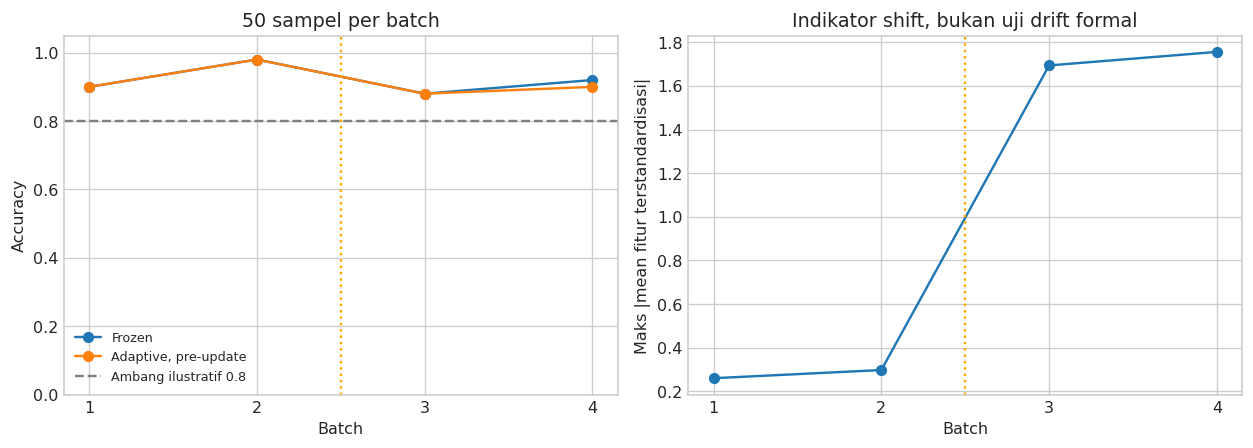

In [ ]:
stream_X,stream_y=make_classification(n_samples=700,n_features=10,n_informative=6,n_redundant=2,random_state=SEED)
base_X,base_y=stream_X[:500],stream_y[:500]
pub_X,pub_y=stream_X[500:].copy(),stream_y[500:].copy()
pub_X[100:,:2]+=3.0  # shift terkontrol pada pengukuran dua fitur, mulai batch 3
stream_scale=StandardScaler().fit(base_X); base_scaled=stream_scale.transform(base_X)
adaptive=SGDClassifier(loss='log_loss',alpha=.001,learning_rate='constant',eta0=.01,random_state=SEED)
rng=np.random.default_rng(SEED)
for _ in range(10):
    order=rng.permutation(len(base_y)); adaptive.partial_fit(base_scaled[order],base_y[order],classes=np.array([0,1]))
frozen=copy.deepcopy(adaptive)
batches=np.array_split(pub_X,4); labels=np.array_split(pub_y,4); stream_rows=[]
for i,(xb,yb) in enumerate(zip(batches,labels),1):
    sb=stream_scale.transform(xb)
    before=adaptive.predict(sb); fixed=frozen.predict(sb)
    stream_rows.append({'batch':i,'n':len(yb),'frozen_accuracy':accuracy_score(yb,fixed),
        'adaptive_accuracy_before_update':accuracy_score(yb,before),
        'max_standardized_mean_shift':np.abs(sb.mean(axis=0)).max()})
    adaptive.partial_fit(sb,yb)  # Label diasumsikan tersedia sesudah prediksi.
stream_result=pd.DataFrame(stream_rows); display(stream_result)
display(Markdown('**Interpretasi monitoring:** periksa apakah pergeseran fitur setelah batch 2 diikuti penurunan accuracy. '
    'Pembaruan adaptive tidak dijamin mengalahkan model frozen pada batch berikutnya; keputusan update perlu divalidasi, bukan diasumsikan selalu membantu.'))
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(stream_result.batch,stream_result.frozen_accuracy,'o-',label='Frozen')
axes[0].plot(stream_result.batch,stream_result.adaptive_accuracy_before_update,'o-',label='Adaptive, pre-update')
axes[0].axhline(.8,color='gray',ls='--',label='Ambang ilustratif 0.8'); axes[0].set(xlabel='Batch',ylabel='Accuracy',ylim=(0,1.05),title='50 sampel per batch'); axes[0].legend(fontsize=8)
axes[1].plot(stream_result.batch,stream_result.max_standardized_mean_shift,'o-'); axes[1].set(xlabel='Batch',ylabel='Maks |mean fitur terstandardisasi|',title='Indikator shift, bukan uji drift formal')
for ax in axes: ax.set_xticks([1,2,3,4]); ax.axvline(2.5,color='orange',ls=':')
plt.tight_layout(); plt.show()

## 5. Versioning dan reproducibility
Versi artefak dan versi library berbeda: `v1.0` adalah identitas rilis model, sedangkan `sklearn.__version__` menyatakan lingkungan pelatihan. Versi hardcoded yang tidak sesuai lingkungan membuat debugging sulit. Seed saja belum menjamin hasil lintas perangkat/versi bit-identik; catat versi paket dan prosedur data.

Resep menggunakan 800×20 dan RF 50 pohon. Kita membagi indeks menjadi **60% training, 20% validation, 20% test** sebelum fit. Validation menginformasikan gerbang rilis; test disisihkan untuk penilaian final setelah gate. Hash split membantu menelusuri pembagian yang dipakai tanpa menyimpan identitas pribadi. Model registry dan rollback di produksi harus menjaga model + preprocessing + schema + dependensi sebagai satu versi.

In [ ]:
V,vy=make_classification(n_samples=800,n_features=20,random_state=SEED)
indices=np.arange(len(vy))
vi_train,vi_rest=train_test_split(indices,test_size=.4,stratify=vy,random_state=SEED)
vi_val,vi_test=train_test_split(vi_rest,test_size=.5,stratify=vy[vi_rest],random_state=2025)
assert not (set(vi_train)&set(vi_val) or set(vi_train)&set(vi_test) or set(vi_val)&set(vi_test))
versioned=RandomForestClassifier(n_estimators=50,random_state=SEED,n_jobs=1).fit(V[vi_train],vy[vi_train])
version='v1.0'; version_path=model_dir/f'rf_{version}.joblib'; dump(versioned,version_path)
validation_acc=accuracy_score(vy[vi_val],versioned.predict(V[vi_val]))
metadata={'model_version':version,'python':platform.python_version(),'sklearn':sklearn.__version__,
    'numpy':np.__version__,'seed':SEED,'dataset':'make_classification: 800 samples, 20 features',
    'classes':versioned.classes_.tolist(),'feature_names':[f'feature_{i:02d}' for i in range(20)],
    'split_sizes':{'train':len(vi_train),'validation':len(vi_val),'test':len(vi_test)},
    'split_sha256':hashlib.sha256(np.concatenate([vi_train,vi_val,vi_test]).astype('<i8').tobytes()).hexdigest(),
    'artifact_sha256':hashlib.sha256(version_path.read_bytes()).hexdigest(),'validation_accuracy':validation_acc}
(model_dir/f'rf_{version}_metadata.json').write_text(json.dumps(metadata,indent=2))
print(json.dumps(metadata,indent=2))

{
  "model_version": "v1.0",
  "python": "3.12.14",
  "sklearn": "1.8.0",
  "numpy": "2.3.5",
  "seed": 2024,
  "dataset": "make_classification: 800 samples, 20 features",
  "classes": [
    0,
    1
  ],
  "feature_names": [
    "feature_00",
    "feature_01",
    "feature_02",
    "feature_03",
    "feature_04",
    "feature_05",
    "feature_06",
    "feature_07",
    "feature_08",
    "feature_09",
    "feature_10",
    "feature_11",
    "feature_12",
    "feature_13",
    "feature_14",
    "feature_15",
    "feature_16",
    "feature_17",
    "feature_18",
    "feature_19"
  ],
  "split_sizes": {
    "train": 480,
    "validation": 160,
    "test": 160
  },
  "split_sha256": "b103bf57a633d073786aaeeda41e3d1e0116606d82746167f2fdbeb5d87434d2",
  "artifact_sha256": "0ff8f990e81c48a4bac7ae8a354200b368658034506b42e7b338bd99e526cafa",
  "validation_accuracy": 0.93125
}


## 6. Simulasi deployment gate
Gate adalah aturan yang ditentukan **sebelum** membaca skor validation. Untuk demo, syaratnya accuracy validation ≥0,80, setidaknya setara baseline mayoritas, schema/angka valid, dan prediksi reload identik. Ambang 0,80 hanya ilustrasi; kebutuhan sistem nyata harus menentukan metrik, biaya kesalahan, latency, serta standar penerimaan.

Gate yang lulus belum berarti model aman/andal di semua situasi. Jika gagal, simpan catatan dan evaluasi ulang rancangan memakai data pengembangan; jangan menurunkan threshold hanya supaya notebook menampilkan “approved”. Test final hanya dibuka setelah gate lulus. Metrik test final adalah konfirmasi, bukan data tuning berikutnya. Tidak ada perintah deploy dijalankan.

In [ ]:
MIN_VALIDATION_ACCURACY=.80
baseline=DummyClassifier(strategy='most_frequent').fit(V[vi_train],vy[vi_train])
baseline_acc=baseline.score(V[vi_val],vy[vi_val])
version_loaded=load(version_path)
gate_checks={'accuracy_minimum':validation_acc>=MIN_VALIDATION_ACCURACY,
    'beats_or_matches_baseline':validation_acc>=baseline_acc,
    'finite_validation_features':bool(np.isfinite(V[vi_val]).all()),
    'expected_feature_count':version_loaded.n_features_in_==20,
    'reload_prediction_equal':bool(np.array_equal(versioned.predict(V[vi_val]),version_loaded.predict(V[vi_val])))}
approved=all(gate_checks.values())
gate_result={'simulation_only':True,'threshold':MIN_VALIDATION_ACCURACY,'baseline_validation_accuracy':baseline_acc,
    'checks':gate_checks,'eligible_for_review':approved}
if approved: gate_result['final_test']=metrics(vy[vi_test],version_loaded.predict(V[vi_test]))
else: gate_result['final_test']='Belum dibuka: gate validation tidak lulus.'
print(json.dumps(gate_result,indent=2)); print('Status: layak ditinjau' if approved else 'Status: perlu perbaikan, tidak dirilis')

{
  "simulation_only": true,
  "threshold": 0.8,
  "baseline_validation_accuracy": 0.5,
  "checks": {
    "accuracy_minimum": true,
    "beats_or_matches_baseline": true,
    "finite_validation_features": true,
    "expected_feature_count": true,
    "reload_prediction_equal": true
  },
  "eligible_for_review": true,
  "final_test": {
    "accuracy": 0.93125,
    "balanced_accuracy": 0.9312499999999999,
    "macro_f1": 0.9312258215778985
  }
}
Status: layak ditinjau


## 7. Latihan 1 — simpan dan muat pipeline
Generator 500×10 mengikuti sumber. Model scaler+logistic disimpan sebagai satu objek, lalu kesamaan prediksi/probabilitas pada holdout diverifikasi. Membandingkan hasil reload dengan model awal menguji konsistensi serialisasi; membandingkan dengan label holdout menguji kemampuan prediksi. Kedua pemeriksaan berbeda.

In [ ]:
E,ey=make_classification(n_samples=500,n_features=10,random_state=SEED)
Et,Ev,et,ev=train_test_split(E,ey,test_size=.3,stratify=ey,random_state=SEED)
exercise_pipeline=make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000,random_state=SEED)).fit(Et,et)
ex_path=model_dir/'exercise_pipeline.joblib'; dump(exercise_pipeline,ex_path); exercise_loaded=load(ex_path)
assert np.allclose(exercise_pipeline.predict_proba(Ev),exercise_loaded.predict_proba(Ev),rtol=0,atol=1e-12)
print('Latihan 1 reload konsisten; holdout:',metrics(ev,exercise_loaded.predict(Ev)))

Latihan 1 reload konsisten; holdout: {'accuracy': 0.88, 'balanced_accuracy': 0.8801564722617354, 'macro_f1': 0.88}


## 8. Latihan 2 — monitoring model hinge dengan regularisasi kuat
Sesuai latihan sumber, `SGDClassifier(loss="hinge", alpha=1.0)` digunakan untuk menunjukkan bahwa model yang underfit dapat bermasalah bahkan sebelum shift. Model ini dilatih pada training referensi dan **dibekukan** selama empat batch; hasil tidak dicampur dengan metrik model adaptive pada Bagian 4. Hinge loss adalah objective margin dan tidak menyediakan probabilitas melalui `predict_proba`.

Accuracy 50 sampel per batch mudah berubah karena variasi sampel. Alarm satu batch di bawah 0,80 merupakan sinyal untuk ditinjau, bukan bukti pasti drift. Dalam sistem nyata, gunakan window yang relevan dan label yang sudah tersedia pada saat pengukuran.

Latihan 2 batch accuracy: [0.86, 0.96, 0.76, 0.92]


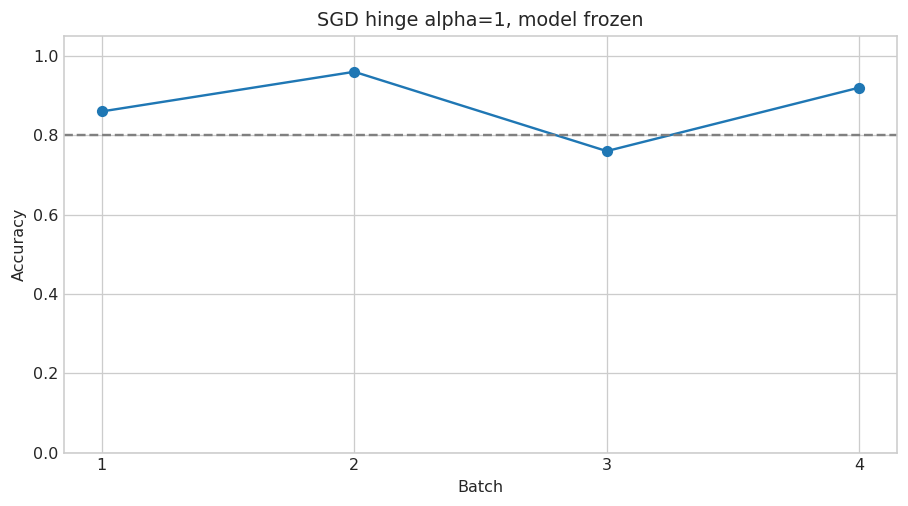

In [ ]:
strong=SGDClassifier(loss='hinge',alpha=1.0,random_state=SEED)
strong.partial_fit(base_scaled,base_y,classes=np.array([0,1]))
strong_scores=[accuracy_score(yb,strong.predict(stream_scale.transform(xb))) for xb,yb in zip(batches,labels)]
print('Latihan 2 batch accuracy:',strong_scores)
fig,ax=plt.subplots(); ax.plot(range(1,5),strong_scores,'o-'); ax.axhline(.8,color='gray',ls='--')
ax.set(xlabel='Batch',ylabel='Accuracy',title='SGD hinge alpha=1, model frozen',ylim=(0,1.05),xticks=[1,2,3,4]); plt.tight_layout(); plt.show()

## 9. Latihan 3 — pemeriksaan CI untuk model kandidat
Solusi sumber membangkitkan train dan test dari dua generator dengan seed berbeda, yang dapat mengubah task. Perbaikan menggunakan satu generator 300×10 kemudian membaginya 60/20/20. Gate hanya melihat validation dan pemeriksaan integritas reload. Test dibuka jika kandidat layak ditinjau. CI nyata juga perlu kontrak input, uji dependensi, evaluasi subgroup yang relevan, dan prosedur pemulihan; tidak semuanya dapat disimpulkan dari dataset sintetis kecil.

In [ ]:
C,cy=make_classification(n_samples=300,n_features=10,random_state=SEED)
Ct,Cr,ct,cr=train_test_split(C,cy,test_size=.4,stratify=cy,random_state=SEED)
Cval,Ctest,cval,ctest=train_test_split(Cr,cr,test_size=.5,stratify=cr,random_state=2025)
candidate=make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000,random_state=SEED)).fit(Ct,ct)
candidate_path=model_dir/'model_ci.joblib'; dump(candidate,candidate_path); candidate_loaded=load(candidate_path)
ci_accuracy=accuracy_score(cval,candidate_loaded.predict(Cval))
ci_baseline=DummyClassifier(strategy='most_frequent').fit(Ct,ct).score(Cval,cval)
ci_checks={'validation_accuracy_ge_080':ci_accuracy>=.8,'at_least_baseline':ci_accuracy>=ci_baseline,
    'reload_equal':bool(np.array_equal(candidate.predict(Cval),candidate_loaded.predict(Cval))),
    'probabilities_sum_to_one':bool(np.allclose(candidate_loaded.predict_proba(Cval).sum(axis=1),1))}
ci_pass=all(ci_checks.values())
ci_result={'validation_n':len(cval),'validation_accuracy':ci_accuracy,'baseline':ci_baseline,'checks':ci_checks,
    'eligible_for_review':ci_pass,'final_test':metrics(ctest,candidate_loaded.predict(Ctest)) if ci_pass else 'Not opened'}
print(json.dumps(ci_result,indent=2))
run_summary={'environment':{'python':platform.python_version(),'sklearn':sklearn.__version__},
    'performance_demo':perf_summary,'stream_batches':stream_result.to_dict('records'),
    'version_metadata':metadata,'main_gate':gate_result,'exercise3_gate':ci_result}
(artifact_dir/'ch13_run_summary.json').write_text(json.dumps(run_summary,indent=2))
display(Markdown('**Analisis hasil:** semua keputusan di atas adalah keluaran aturan yang ditetapkan sebelumnya. '
    'Keberhasilan reload menguji konsistensi artefak, bukan generalisasi. Hasil monitoring memakai prediksi sebelum update. '
    'Status gate hanya kelayakan untuk peninjauan; notebook ini tidak menerbitkan model.'))

{
  "validation_n": 60,
  "validation_accuracy": 0.8666666666666667,
  "baseline": 0.5,
  "checks": {
    "validation_accuracy_ge_080": true,
    "at_least_baseline": true,
    "reload_equal": true,
    "probabilities_sum_to_one": true
  },
  "eligible_for_review": true,
  "final_test": {
    "accuracy": 0.9166666666666666,
    "balanced_accuracy": 0.9166666666666667,
    "macro_f1": 0.9166435120866907
  }
}


**Analisis hasil:** semua keputusan di atas adalah keluaran aturan yang ditetapkan sebelumnya. Keberhasilan reload menguji konsistensi artefak, bukan generalisasi. Hasil monitoring memakai prediksi sebelum update. Status gate hanya kelayakan untuk peninjauan; notebook ini tidak menerbitkan model.

## Ringkasan chapter
Deployment memerlukan pipeline yang konsisten, kontrak input, versi yang terlacak dan evaluasi terpisah. Serialisasi harus diuji dengan prediksi identik dan hanya dimuat dari sumber terpercaya. Performa inferensi perlu diukur pada beban relevan. Monitoring dan pembaruan memerlukan urutan prediksi-sebelum-update, sedangkan gate validation membantu keputusan yang dapat ditinjau tanpa menggunakan test untuk tuning.

## Refleksi untuk dikerjakan sendiri
1. Mengapa menyimpan scaler terpisah tanpa versi dapat mengubah hasil inferensi?
2. Apa perbedaan memeriksa hash artefak dan mempercayai pihak pembuat artefak?
3. Mengapa label acak pada vektor uniform bukan validasi yang masuk akal bagi classifier ini?
4. Jika akurasi batch turun, bukti apa yang perlu diperiksa sebelum retraining dan mengganti model aktif?

## Referensi dan atribusi
- John Sukup. *scikit-learn Cookbook*, Third Edition. Packt Publishing, 2025. Kode pendamping Chapter 13 dan solusi latihan: [repository resmi](https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition/tree/c624b1279cf23a83273e806cede15cad0c9e5500).
- [Model persistence](https://scikit-learn.org/1.8/model_persistence.html).
- [Computational performance](https://scikit-learn.org/1.8/computing/computational_performance.html).
- [Scaling strategies dan incremental learning](https://scikit-learn.org/1.8/computing/scaling_strategies.html).
- [Joblib persistence](https://joblib.readthedocs.io/en/stable/persistence.html).
- Kode sumber pendamping berlisensi MIT; teks lisensi dipertahankan pada `THIRD_PARTY_NOTICES.md`. Penjelasan, koreksi metodologi, dan eksperimen tambahan pada notebook ini merupakan adaptasi belajar berbantuan AI. Baca, jalankan ulang, dan tulis refleksi pribadi sebelum menyerahkan tugas; jangan menyatakan bagian berbantuan AI sebagai pekerjaan mandiri tanpa mengikuti kebijakan kelas.